<a href="https://colab.research.google.com/github/05537613940ssg-svg/ppg-nabiz-kestirimi/blob/main/sefaerogluproje_md.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Gerçek EKG nabızlarının bulunduğu ana referans dosyasını linkten oku
url_ann = "https://physionet.org/files/butppg/2.0.0/quality-hr-ann.csv"
ann = pd.read_csv(url_ann)

# 2. Dosyanın içeriğini ve sütunlarını kontrol et
print("--- REFERANS TABLOSU İLK 5 SATIR ---")
print(ann.head())
print("\nToplam satır sayısı:", len(ann))
print("Sütun adları:", list(ann.columns))

--- REFERANS TABLOSU İLK 5 SATIR ---
       ID  Quality  HR
0  100001        1  83
1  100002        1  85
2  100003        1  81
3  100004        0  85
4  101001        1  67

Toplam satır sayısı: 3888
Sütun adları: ['ID', 'Quality', 'HR']


--- İLK KAYIT SONUÇLARI (100001) ---
Örnekleme Frekansı: 30 Hz
Toplam Örnek Sayısı: 300 (Süre: 10.0 saniye)
Gerçek EKG Nabzı: 83 atım/dk
Ham Tepe Sayısı: 71 adet
Ham Tahmin Nabız: 426.0 atım/dk
İlk Kayıt Hatası: 343.0 atım/dk


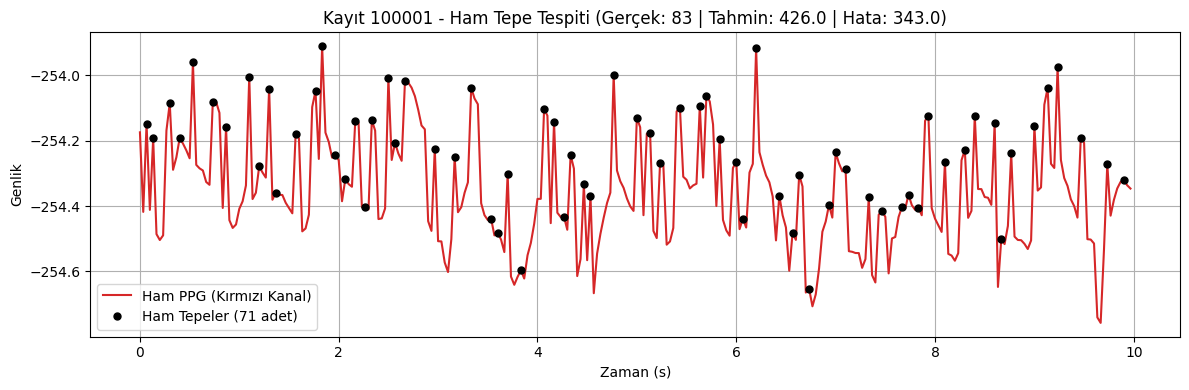

In [31]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# 1. İlk hastanın ID'sini ve referans EKG nabzını al
kayit_id = ann['ID'].iloc[0]
gercek_hr = ann['HR'].iloc[0]

# 2. Sinyali doğrudan PhysioNet üzerinden oku
record = wfdb.rdrecord(f"{kayit_id}_PPG", pn_dir=f"butppg/2.0.0/{kayit_id}")
fs = record.fs  # 30 Hz
raw_sig = record.p_signal

# Matris yapısını analiz et ve hocanın kuralına göre kırmızı kanalı al
if raw_sig.shape[0] == 1:
    # 1x300 yatay vektör durumu
    ppg = raw_sig.flatten()
elif raw_sig.ndim == 2 and raw_sig.shape[1] >= 3:
    # 3 sütunlu (RGB) durum: İlk sütun kırmızı kanaldır
    ppg = raw_sig[:, 0]
elif raw_sig.ndim == 2 and raw_sig.shape[0] >= 3 and raw_sig.shape[1] > raw_sig.shape[0]:
    # 3 satırlı (RGB) durum: İlk satır kırmızı kanaldır
    ppg = raw_sig[0, :]
else:
    ppg = raw_sig.flatten()

# 3. Zaman ekseni ve süre hesabı
ornek_sayisi = len(ppg)
sure = ornek_sayisi / fs
zaman = np.arange(ornek_sayisi) / fs

# 4. Baseline: Ham tepe sayımı (filtresiz doğrudan yerel tepe bulma)
tepeler, _ = find_peaks(ppg)
tepe_sayisi = len(tepeler)

# 10 saniyedeki tepe adedini dakikalık nabza (atım/dk) çevir
tahmin_hr = tepe_sayisi * (60.0 / sure)
hata = abs(tahmin_hr - gercek_hr)

print(f"--- İLK KAYIT SONUÇLARI ({kayit_id}) ---")
print(f"Örnekleme Frekansı: {fs} Hz")
print(f"Toplam Örnek Sayısı: {ornek_sayisi} (Süre: {sure:.1f} saniye)")
print(f"Gerçek EKG Nabzı: {gercek_hr} atım/dk")
print(f"Ham Tepe Sayısı: {tepe_sayisi} adet")
print(f"Ham Tahmin Nabız: {tahmin_hr:.1f} atım/dk")
print(f"İlk Kayıt Hatası: {hata:.1f} atım/dk")

# 5. Sinyali ve tespit edilen ham tepeleri çiz ve kaydet
plt.figure(figsize=(12, 4))
plt.plot(zaman, ppg, label='Ham PPG (Kırmızı Kanal)', color='tab:red')
plt.plot(zaman[tepeler], ppg[tepeler], 'ko', markersize=5, label=f'Ham Tepeler ({tepe_sayisi} adet)')
plt.title(f"Kayıt {kayit_id} - Ham Tepe Tespiti (Gerçek: {gercek_hr} | Tahmin: {tahmin_hr:.1f} | Hata: {hata:.1f})")
plt.xlabel("Zaman (s)")
plt.ylabel("Genlik")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig('sekil1.png', dpi=150)
plt.show()

In [32]:
import urllib.request

# Başlık dosyasının (.hea) içeriğini doğrudan oku ve yazdır
hea_metni = urllib.request.urlopen("https://physionet.org/files/butppg/2.0.0/100001/100001_PPG.hea").read().decode()
print("100001_PPG.hea içeriği:\n")
print(hea_metni)

100001_PPG.hea içeriği:

100001_PPG 300 30 1
100001_PPG.dat 16 -128.9152(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.792(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.9284(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.7951(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.9058(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.7576(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.7485(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.7557(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.9179(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.9603(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.8572(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.8765(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.9064(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.8977(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.8874(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.875(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -129.024(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.8648(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128

In [33]:
# 1. Referans tablosundaki ilk 10 kaydı al
ilk_10_df = ann.head(10)

hatalar = []
bes_alti_sayisi = 0

print("--- İLK 10 KAYIT İÇİN BASELINE (HAM TEPE) ANALİZİ ---")

for i, row in ilk_10_df.iterrows():
    kid = row['ID']
    gercek_hr = row['HR']

    # Sinyali doğrudan oku
    rec = wfdb.rdrecord(f"{kid}_PPG", pn_dir=f"butppg/2.0.0/{kid}")
    fs = rec.fs
    raw_sig = rec.p_signal

    # Kırmızı kanalı (ilk kanal/satır) ayıkla
    if raw_sig.shape[0] == 1:
        ppg = raw_sig.flatten()
    elif raw_sig.ndim == 2 and raw_sig.shape[1] >= 3:
        ppg = raw_sig[:, 0]
    elif raw_sig.ndim == 2 and raw_sig.shape[0] >= 3 and raw_sig.shape[1] > raw_sig.shape[0]:
        ppg = raw_sig[0, :]
    else:
        ppg = raw_sig.flatten()

    sure = len(ppg) / fs

    # Ham tepe sayımı (Baseline)
    tepeler, _ = find_peaks(ppg)
    tepe_sayisi = len(tepeler)
    tahmin_hr = tepe_sayisi * (60.0 / sure)

    hata = abs(tahmin_hr - gercek_hr)
    hatalar.append(hata)

    if hata < 5.0:
        bes_alti_sayisi += 1

    print(f"Kayıt {kid}: Gerçek = {gercek_hr:2d} | Tahmin = {tahmin_hr:5.1f} | Hata = {hata:5.1f} atım/dk")

baseline_mae = np.mean(hatalar)
yuzde_5 = (bes_alti_sayisi / len(ilk_10_df)) * 100.0

print("\n" + "="*45)
print(f"İLK SAYIN (BASELINE MAE): {baseline_mae:.2f} atım/dk")
print(f"Hatası < 5 atım/dk Kalan Kayıt Oranı: %{yuzde_5:.1f}")
print("="*45)

--- İLK 10 KAYIT İÇİN BASELINE (HAM TEPE) ANALİZİ ---
Kayıt 100001: Gerçek = 83 | Tahmin = 426.0 | Hata = 343.0 atım/dk
Kayıt 100002: Gerçek = 85 | Tahmin = 360.0 | Hata = 275.0 atım/dk
Kayıt 100003: Gerçek = 81 | Tahmin = 402.0 | Hata = 321.0 atım/dk
Kayıt 100004: Gerçek = 85 | Tahmin = 198.0 | Hata = 113.0 atım/dk
Kayıt 101001: Gerçek = 67 | Tahmin = 204.0 | Hata = 137.0 atım/dk
Kayıt 101002: Gerçek = 69 | Tahmin = 174.0 | Hata = 105.0 atım/dk
Kayıt 101003: Gerçek = 71 | Tahmin = 264.0 | Hata = 193.0 atım/dk
Kayıt 101004: Gerçek = 67 | Tahmin = 162.0 | Hata =  95.0 atım/dk
Kayıt 102001: Gerçek = 68 | Tahmin = 354.0 | Hata = 286.0 atım/dk
Kayıt 102002: Gerçek = 66 | Tahmin = 324.0 | Hata = 258.0 atım/dk

İLK SAYIN (BASELINE MAE): 212.60 atım/dk
Hatası < 5 atım/dk Kalan Kayıt Oranı: %0.0


In [34]:
from scipy.signal import butter, filtfilt

# 1. Filtre ve FFT parametreleri
# Nabız aralığı: 45 - 210 atım/dk -> 0.75 Hz - 3.5 Hz
f_alt = 0.75
f_ust = 3.5

hatalar_fft = []
bes_alti_fft_sayisi = 0

print("--- İLK İYİLEŞTİRME: FİLTRE + FOURIER (FFT) ANALİZİ ---")

for i, row in ilk_10_df.iterrows():
    kid = row['ID']
    gercek_hr = row['HR']

    # Sinyali oku ve kırmızı kanalı al
    rec = wfdb.rdrecord(f"{kid}_PPG", pn_dir=f"butppg/2.0.0/{kid}")
    fs = rec.fs
    raw_sig = rec.p_signal

    if raw_sig.shape[0] == 1:
        ppg = raw_sig.flatten()
    elif raw_sig.ndim == 2 and raw_sig.shape[1] >= 3:
        ppg = raw_sig[:, 0]
    elif raw_sig.ndim == 2 and raw_sig.shape[0] >= 3 and raw_sig.shape[1] > raw_sig.shape[0]:
        ppg = raw_sig[0, :]
    else:
        ppg = raw_sig.flatten()

    # 2. H5 konusu: Butterworth Bant Geçiren Filtre (Gürültüyü ve taban kaymasını at)
    b, a = butter(2, [f_alt, f_ust], btype='bandpass', fs=fs)
    ppg_filt = filtfilt(b, a, ppg)

    # Ortalama değeri çıkar (DC bileşeni sıfırla)
    ppg_filt = ppg_filt - np.mean(ppg_filt)

    # 3. H4 konusu: Fourier Analizi (FFT) - Frekans çözünürlüğü için sıfır doldurma (zero-padding)
    n_fft = 3000
    fft_genlik = np.abs(np.fft.rfft(ppg_filt, n=n_fft))
    frekanslar = np.fft.rfftfreq(n_fft, d=1/fs)

    # Yalnızca nabız frekansı bandına odaklan
    bant = (frekanslar >= f_alt) & (frekanslar <= f_ust)
    baskintepe_frekans = frekanslar[bant][np.argmax(fft_genlik[bant])]

    # Frekansı (Hz) dakikalık nabza (atım/dk) dönüştür: HR = f * 60
    tahmin_fft_hr = baskintepe_frekans * 60.0

    hata_fft = abs(tahmin_fft_hr - gercek_hr)
    hatalar_fft.append(hata_fft)

    if hata_fft < 5.0:
        bes_alti_fft_sayisi += 1

    print(f"Kayıt {kid}: Gerçek = {gercek_hr:2d} | FFT Tahmin = {tahmin_fft_hr:5.1f} | Hata = {hata_fft:4.1f} atım/dk")

iyilestirilmis_mae = np.mean(hatalar_fft)
yuzde_5_fft = (bes_alti_fft_sayisi / len(ilk_10_df)) * 100.0

print("\n" + "="*50)
print(f"İLK SAYIN (BASELINE MAE)     : {baseline_mae:.2f} atım/dk")
print(f"İYİLEŞTİRİLMİŞ YÖNTEM MAE     : {iyilestirilmis_mae:.2f} atım/dk")
print(f"Hata < 5 atım/dk Başarı Oranı: %{yuzde_5_fft:.1f}")
print("="*50)

--- İLK İYİLEŞTİRME: FİLTRE + FOURIER (FFT) ANALİZİ ---
Kayıt 100001: Gerçek = 83 | FFT Tahmin =  82.8 | Hata =  0.2 atım/dk
Kayıt 100002: Gerçek = 85 | FFT Tahmin =  84.0 | Hata =  1.0 atım/dk
Kayıt 100003: Gerçek = 81 | FFT Tahmin =  81.6 | Hata =  0.6 atım/dk
Kayıt 100004: Gerçek = 85 | FFT Tahmin = 159.0 | Hata = 74.0 atım/dk
Kayıt 101001: Gerçek = 67 | FFT Tahmin =  66.6 | Hata =  0.4 atım/dk
Kayıt 101002: Gerçek = 69 | FFT Tahmin =  69.0 | Hata =  0.0 atım/dk
Kayıt 101003: Gerçek = 71 | FFT Tahmin =  70.8 | Hata =  0.2 atım/dk
Kayıt 101004: Gerçek = 67 | FFT Tahmin =  94.8 | Hata = 27.8 atım/dk
Kayıt 102001: Gerçek = 68 | FFT Tahmin =  67.2 | Hata =  0.8 atım/dk
Kayıt 102002: Gerçek = 66 | FFT Tahmin =  66.0 | Hata =  0.0 atım/dk

İLK SAYIN (BASELINE MAE)     : 212.60 atım/dk
İYİLEŞTİRİLMİŞ YÖNTEM MAE     : 10.50 atım/dk
Hata < 5 atım/dk Başarı Oranı: %80.0
